# Assignment 5: Predicting Iris Species

In this report, I compare four machine learning methods—support vector machine (SVM), random forest, neural network, and Naive Bayes—for predicting iris species based on petal and sepal measurements. I evaluate their performance using stratified five-fold cross-validation, examine whether hyperparameter tuning improves SVM performance, and explore how different sets of features affect classification accuracy. Based on these analyses, I identify the most promising method for predicting iris species.


## Summary of Findings

The main findings are:

- Naive Bayes performed best among the default models, with 96.0% accuracy and a macro F1-score of 0.960, followed by SVM (95.3% accuracy), random forest (94.0%), and neural network (91.3%).
- Hyperparameter tuning slightly improved SVM performance, increasing accuracy from 95.3% to 96.0%.
- Petal measurements were much more informative than sepal measurements. Using only petals, SVM achieved 96.0% accuracy, compared with 81.3% using only sepals and 95.3% using all four measurements.
- Most classification errors involved versicolor and virginica. With sepal measurements, SVM confused these two species 27 times, compared with only 6 times using petal measurements.

Based on these results, I recommend Naive Bayes for predicting iris species, since it achieved the highest accuracy and macro F1-score among the default models without requiring hyperparameter tuning.

## 1. Import packages and define table style

In [1]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_predict
from sklearn.naive_bayes import GaussianNB

import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

#Table style
def style_table(df):
    return (
        df.style
        .format(precision=3)
        .hide(axis="index")
        .set_table_styles([
            {"selector": "th", "props": [
                ("background-color", "#243B53"),
                ("color", "white"),
                ("padding", "10px 16px"),
                ("text-align", "left")
            ]},
            {"selector": "td", "props": [
                ("padding", "9px 16px"),
                ("border-bottom", "1px solid #E5E7EB")
            ]},
            {"selector": "tr:nth-child(even)", "props": [
                ("background-color", "#F3F6FA")
            ]}
        ])
    )

## 2. The Iris Dataset

In [2]:
# Load the Iris dataset
iris = pd.read_csv("iris.data", header=None)

# Name the columns
iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]

# Extract features and class labels
X = iris.drop(columns="class")
y = iris["class"]

# Number of observations
print(len(y))
print(len(X))

150
150


In [3]:
# Number of features
k_features = X.shape[1]
print(k_features)

# Check for missing values
print(X.isnull().sum())
print(y.isnull().sum())

4
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
dtype: int64
0


In [4]:
# Compute proportions of each class
table_y = pd.crosstab(y, "Species") / len(y)

# Move species names from the index into a regular column
table_y = table_y.reset_index()
table_y.columns = ["Iris Species", "Proportion"]

display(Markdown("**Table 1. Distribution of Iris Species**"))
display(style_table(table_y))

**Table 1. Distribution of Iris Species**

Iris Species,Proportion
Iris-setosa,0.333
Iris-versicolor,0.333
Iris-virginica,0.333


In [5]:
# Compute descriptive statistics for features
descriptive_stats = X.describe().reset_index()
descriptive_stats = descriptive_stats.rename(columns={"index": "Statistic"})
descriptive_stats = descriptive_stats.rename(columns={
    "sepal_length": "Sepal Length",
    "sepal_width": "Sepal Width",
    "petal_length": "Petal Length",
    "petal_width": "Petal Width"
})

display(Markdown("**Table 2. Descriptive Statistics of Iris Measurements**"))
display(style_table(descriptive_stats))

**Table 2. Descriptive Statistics of Iris Measurements**

Statistic,Sepal Length,Sepal Width,Petal Length,Petal Width
count,150.000,150.000,150.000,150.000
mean,5.843,3.054,3.759,1.199
std,0.828,0.434,1.764,0.763
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


The dataset contains 150 observations and four features: sepal length, sepal width, petal length, and petal width. There are three iris species (setosa, versicolor, and virginica), each making up one-third of the dataset. I also checked for missing values and found none, so no observations needed to be dropped. Looking at the descriptive statistics, petal length varies the most across observations, while sepal width varies the least.

## 3. Comparing Machine Learning Methods

I compare four machine learning methods to predict iris species: support vector machines (SVM), random forests, neural networks, and gaussian naive bayes.

I use stratified five-fold cross-validation to evaluate the models. For each model, the data are divided into five folds, with four used for training and one for testing. Stratification ensures that each fold contains the same proportion of the three iris species. This process is repeated five times, and I compare the average performance across the folds.

I use two evaluation metrics: accuracy and macro F1. I initially considered using accuracy and macro recall; however, because the Iris dataset contains an equal number of observations in each class and stratified cross-validation preserves this balance, the two metrics produce identical values. I therefore use accuracy and macro F1-score instead. Accuracy measures the overall proportion of correct predictions, while macro F1-score combines precision and recall for each class and averages the scores across the three species.

In [6]:
# Set up stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Evaluation metrics
scoring = ["accuracy", "f1_macro"]

In [7]:
# SVM with standardized features
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

# Evaluate using cross-validation
svm_cv = cross_validate(
    svm_model,
    X,
    y,
    scoring=scoring,
    return_train_score=False,
    cv=cv
)

# Average performance across folds
print("Mean accuracy:", round(np.mean(svm_cv["test_accuracy"]), 3))
print("Mean macro F1:", round(np.mean(svm_cv["test_f1_macro"]), 3))

Mean accuracy: 0.953
Mean macro F1: 0.953


In [8]:
# Random Forest model
rf_model = RandomForestClassifier(random_state=0)

# Evaluate using cross-validation
rf_cv = cross_validate(
    rf_model,
    X,
    y,
    scoring=scoring,
    return_train_score=False,
    cv=cv
)

# Average performance across folds
print("Mean accuracy:", round(np.mean(rf_cv["test_accuracy"]), 3))
print("Mean macro F1:", round(np.mean(rf_cv["test_f1_macro"]), 3))

Mean accuracy: 0.94
Mean macro F1: 0.939


Note: For the following neural network, I followed the architecture and training settings demonstrated in Lecture 16, adapting the output layer and loss function to accommodate the three iris species. I did not perform any hyperparameter tuning for this model.

In [9]:
# Convert species labels to numeric values
y_nn = pd.Categorical(y).codes

# Check the class labels
print(pd.DataFrame({
    "Species": pd.Categorical(y).categories,
    "Code": range(3)
}))

           Species  Code
0      Iris-setosa     0
1  Iris-versicolor     1
2   Iris-virginica     2


In [10]:
# Store cross-validation results
nn_accuracy = []
nn_f1 = []

# Run 5-fold cross-validation
for train_index, test_index in cv.split(X, y_nn):

    # Split into training and test data
    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]
    y_train = y_nn[train_index]
    y_test = y_nn[test_index]

    # Standardize features using the training data
    scaler = StandardScaler().fit(X_train)
    X_train_scale = scaler.transform(X_train)
    X_test_scale = scaler.transform(X_test)

    # Set random seed
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(0)

    # Build neural network
    basic_model = keras.models.Sequential()

    basic_model.add(keras.Input(shape=(k_features,)))
    basic_model.add(Dense(units=16, activation='relu'))
    basic_model.add(Dense(units=3, activation='softmax'))

    # Define optimizer
    adam = keras.optimizers.Adam(learning_rate=0.001)

    # Compile model
    basic_model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=adam,
        metrics=["accuracy"]
    )

    # Train model
    basic_model.fit(
        X_train_scale, y_train,
        epochs=100,
        verbose=0
    )

    # Predict class labels
    predictions = basic_model(X_test_scale, training=False).numpy()
    y_pred = np.argmax(predictions, axis=1)

    # Calculate evaluation metrics
    nn_accuracy.append(accuracy_score(y_test, y_pred))
    nn_f1.append(f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    ))

# Average performance across folds
print("Mean accuracy:", round(np.mean(nn_accuracy), 3))
print("Mean macro F1:", round(np.mean(nn_f1), 3))


Mean accuracy: 0.913
Mean macro F1: 0.912


In [11]:
# Gaussian Naive Bayes model
nb_model = GaussianNB()

# Evaluate using cross-validation
nb_results = cross_validate(
    nb_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

# Average performance across folds
print("Mean accuracy:", round(np.mean(nb_results["test_accuracy"]), 3))
print("Mean macro F1:", round(np.mean(nb_results["test_f1_macro"]), 3))


Mean accuracy: 0.96
Mean macro F1: 0.96


In [12]:
# Compare average performance across models
comparison = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "Neural Network", "Naive Bayes"],
    "Mean Accuracy": [
        np.mean(svm_cv["test_accuracy"]),
        np.mean(rf_cv["test_accuracy"]),
        np.mean(nn_accuracy),
        np.mean(nb_results["test_accuracy"])
    ],
    "Mean Macro F1": [
        np.mean(svm_cv["test_f1_macro"]),
        np.mean(rf_cv["test_f1_macro"]),
        np.mean(nn_f1),
        np.mean(nb_results["test_f1_macro"])
    ]
})

comparison = comparison.sort_values("Mean Accuracy", ascending=False)

display(Markdown("**Table 3. Cross-Validation Performance by Classification Method**"))
display(style_table(comparison))

**Table 3. Cross-Validation Performance by Classification Method**

Model,Mean Accuracy,Mean Macro F1
Naive Bayes,0.960,0.960
SVM,0.953,0.953
Random Forest,0.940,0.939
Neural Network,0.913,0.912


Naive Bayes performed best among the four methods, with an average accuracy of 96.0% and a macro F1-score of 0.960. SVM was a close second, with 95.3% accuracy and a macro F1-score of 0.953, followed by random forest (94.0% accuracy, 0.939 macro F1) and the neural network (91.3% accuracy, 0.912 macro F1). The two evaluation metrics produced very similar results, and the ranking of the models was consistent across both. Overall, Naive Bayes appears to be the most promising method for predicting iris species, although SVM and random forest also performed well. In the next section, I examine whether tuning the SVM's parameters can improve its performance.


## 4. Hyperparameter Tuning
I chose SVM for hyperparameter tuning. Using GridSearchCV, I tested 16 combinations of C and gamma, with stratified five-fold cross-validation.

In [13]:
# Hyperparameter tuning for SVM
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1]
}

grid = GridSearchCV(
    svm_model,
    param_grid,
    cv=cv,
    scoring="accuracy"
)

grid.fit(X, y)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 3))

Best parameters: {'svm__C': 10, 'svm__gamma': 0.01}
Best cross-validation accuracy: 0.96


The best-performing combination was C = 10 and gamma = 0.01. Compared with the default SVM, cross-validation accuracy increased from 95.3% to 96.0%. This suggests that adjusting the SVM's parameters can slightly improve its performance, although the improvement was relatively small. The tuned SVM achieved the same accuracy as the default Naive Bayes model. However, since the best parameters were selected using the same cross-validation folds, the tuned accuracy may be somewhat optimistic.

## 5. Additional Analysis: Do We Need All Four Measurements?

So far, I have compared different machine learning methods using all four iris measurements. For this additional analysis, I wanted to see how much the choice of features matters for prediction.

I compare three versions of the SVM model: one using only sepal measurements, one using only petal measurements, and one using all four measurements. I use the same five-fold cross-validation and evaluation metrics as before to see whether including more features actually improves classification.

In [14]:
# Define feature sets
feature_sets = {
    "Sepal only": ["sepal_length", "sepal_width"],
    "Petal only": ["petal_length", "petal_width"],
    "All four": X.columns.tolist()
}

# Compare SVM performance across feature sets
feature_results = []

for name, features in feature_sets.items():
    scores = cross_validate(
        svm_model,
        X[features],
        y,
        scoring=scoring,
        return_train_score=False,
        cv=cv
    )

    feature_results.append({
        "Feature Set": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_f1_macro"].mean()
    })

feature_comparison = pd.DataFrame(feature_results)

display(Markdown("**Table 4. SVM Performance by Feature Set**"))
display(style_table(feature_comparison))

**Table 4. SVM Performance by Feature Set**

Feature Set,Accuracy,Macro F1
Sepal only,0.813,0.812
Petal only,0.960,0.960
All four,0.953,0.953


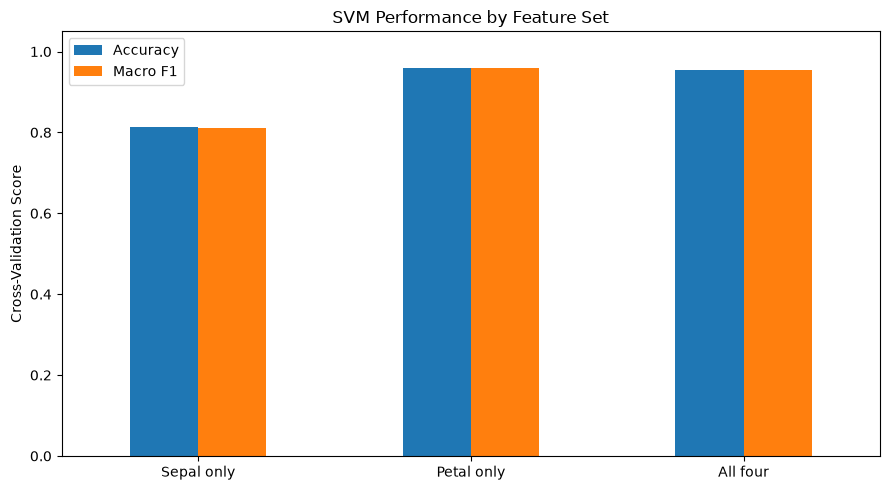

In [15]:
# Plot accuracy and macro F1 by feature set
ax = feature_comparison.set_index("Feature Set").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("SVM Performance by Feature Set")
ax.set_ylabel("Cross-Validation Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)

plt.legend(title="")
plt.tight_layout()
plt.show()

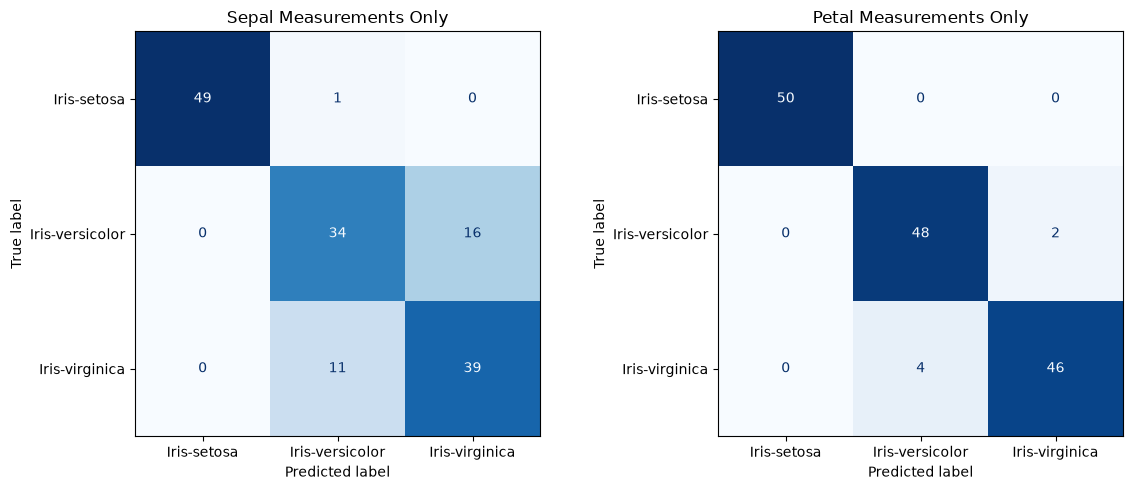

In [16]:
# Cross-validated predictions for each feature set
sepal_pred = cross_val_predict(
    svm_model,
    X[feature_sets["Sepal only"]],
    y,
    cv=cv
)

petal_pred = cross_val_predict(
    svm_model,
    X[feature_sets["Petal only"]],
    y,
    cv=cv
)

# Compare confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y, sepal_pred,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Sepal Measurements Only")

ConfusionMatrixDisplay.from_predictions(
    y, petal_pred,
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)
axes[1].set_title("Petal Measurements Only")

plt.tight_layout()
plt.show()


Petal measurements are much more useful than sepal measurements for predicting iris species. Using only petals, the SVM achieved 96.0% accuracy, compared with 81.3% using only sepals. Interestingly, including all four measurements resulted in slightly lower accuracy (95.3%) than using only petals.

The confusion matrices help explain this difference. Setosa was classified almost perfectly with either feature set. However, using only sepal measurements, the model frequently confused versicolor and virginica, misclassifying 27 observations between these two species. With petal measurements, this number dropped to just 6. This suggests that petal measurements are particularly important for distinguishing versicolor from virginica. It also shows that adding more features does not necessarily improve prediction.

## 6. Discussion and Recommendation

Overall, Naive Bayes performed best among the four methods, with an average cross-validation accuracy of 96.0% and a macro F1-score of 0.960. SVM was a close second, with 95.3% accuracy and a macro F1-score of 0.953. Hyperparameter tuning increased SVM accuracy to 96.0%, matching Naive Bayes. Random forest also performed well, with 94.0% accuracy, while the neural network had the lowest accuracy at 91.3%.

Based on these results, I would recommend Naive Bayes for predicting iris species. It achieved the highest accuracy and macro F1-score among the default models without requiring hyperparameter tuning. Although the tuned SVM achieved the same accuracy, Naive Bayes would be my preference because it performed equally well with its default settings.

The additional analysis also showed that the choice of features matters. Using only petal measurements, SVM achieved 96.0% accuracy, slightly higher than when using all four measurements (95.3%). The confusion matrices showed that sepal measurements were particularly poor at distinguishing versicolor from virginica. This suggests that the information provided to the model can be just as important as the choice of algorithm.

There are some limitations to these results. The Iris dataset is relatively small, with only 150 observations, so the results may depend on how the data are divided into cross-validation folds. Also, the tuned SVM was evaluated using the same cross-validation procedure used to select its parameters, which may make its reported performance slightly optimistic. 